# 01 – Fundamentals: Ev Enerji Verisini Keşfetme

Bu notebook'ta CSV dosyasını açacak, ilk kayıtları inceleyecek, bir gün seçecek ve `Appliances` tüketimini grafikle göstereceğiz. Son olarak günlük toplamı Wh ve kWh cinsinden hesaplayacağız.

**Ön koşul:** `energydata_complete.csv` dosyası proje kökündeki `data/raw/` klasöründe bulunmalı. Bu çalışmada model eğitimi yapılmaz.

## 1. Gerekli kütüphaneler

`pandas` tablo verisiyle, `matplotlib` ise grafiklerle çalışmamızı sağlar.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

# Proje kökünü ve src klasörünü Python'ın arama yoluna ekle.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists() and (PROJECT_ROOT.parent / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from energy_forecast.data_analysis.data_loader import load_energy_data

## 2. CSV dosyasını yükle

Hazırladığımız `load_energy_data()` fonksiyonu dosyayı okur ve tarihleri, gerekli sütunları ve 10 dakikalık aralıkları kontrol eder. Dosya bulunamazsa önce `data/raw/` konumunu kontrol et.

In [2]:
data = load_energy_data()
print("Veri başarıyla yüklendi.")
print(f"Satır sayısı: {len(data):,}")
print(f"Sütun sayısı: {len(data.columns)}")

Veri başarıyla yüklendi.
Satır sayısı: 19,735
Sütun sayısı: 29


## 3. İlk satırları incele

`head()` tablonun ilk beş satırını gösterir. `Appliances` sütunu 10 dakikalık ölçüm aralığındaki enerji tüketimini **Wh** cinsinden verir.

In [3]:
data.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


Sütun adlarını ve veri türlerini de inceleyelim. `date` tarih, `Appliances` ise sayısal enerji tüketimi değeridir.

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[us]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7         19

## 4. Bir gün seç

Önce veri setinde bulunan günleri listele. Ardından aşağıdaki `selected_day` değerini listeden istediğin bir tarihle değiştir. Tam bir günün 10 dakikalık 144 kaydı bulunur; veri setinin başlangıç ve bitiş günleri kısmi olabilir.

In [5]:
available_days = sorted(data["date"].dt.date.unique())
print(f"Veri setindeki gün sayısı: {len(available_days)}")
print("İlk 10 gün:", available_days[:10])
print("Son 10 gün:", available_days[-10:])

Veri setindeki gün sayısı: 138
İlk 10 gün: [datetime.date(2016, 1, 11), datetime.date(2016, 1, 12), datetime.date(2016, 1, 13), datetime.date(2016, 1, 14), datetime.date(2016, 1, 15), datetime.date(2016, 1, 16), datetime.date(2016, 1, 17), datetime.date(2016, 1, 18), datetime.date(2016, 1, 19), datetime.date(2016, 1, 20)]
Son 10 gün: [datetime.date(2016, 5, 18), datetime.date(2016, 5, 19), datetime.date(2016, 5, 20), datetime.date(2016, 5, 21), datetime.date(2016, 5, 22), datetime.date(2016, 5, 23), datetime.date(2016, 5, 24), datetime.date(2016, 5, 25), datetime.date(2016, 5, 26), datetime.date(2016, 5, 27)]


In [6]:
# Listeden bir gün seç. İstersen tarihi değiştir.
selected_day = available_days[1]

daily_data = data[data["date"].dt.date == selected_day].copy()
print(f"Seçilen gün: {selected_day}")
print(f"Kayıt sayısı: {len(daily_data)}")

if daily_data.empty:
    raise ValueError("Seçilen gün için veri bulunamadı.")

Seçilen gün: 2016-01-12
Kayıt sayısı: 144


## 5. 10 dakikalık tüketim grafiği

Yatay eksende ölçüm zamanı, dikey eksende `Appliances` tüketimi yer alır. Her nokta bir 10 dakikalık ölçüm aralığını temsil eder.

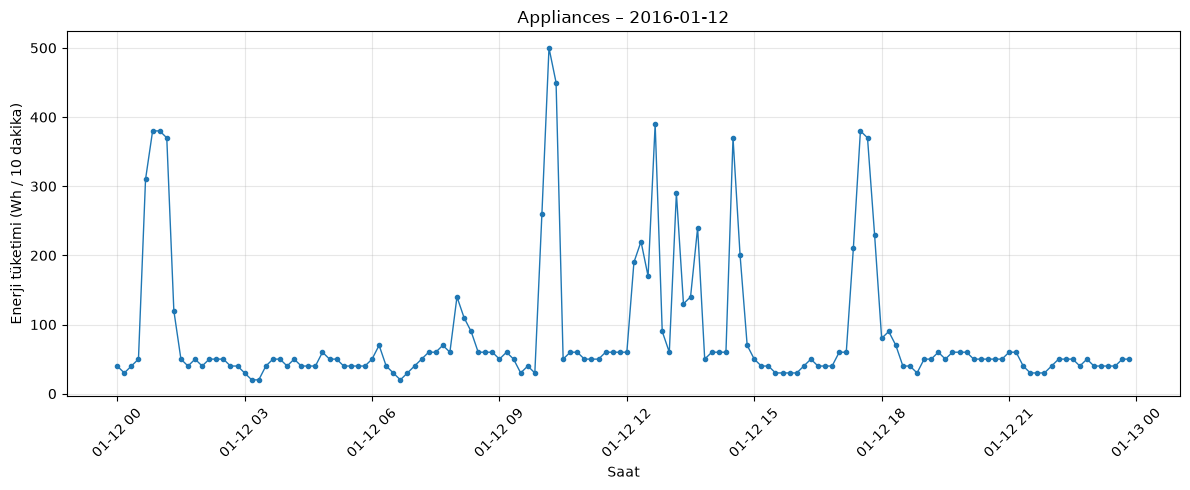

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(daily_data["date"], daily_data["Appliances"], marker=".", linewidth=1)
plt.title(f"Appliances – {selected_day}")
plt.xlabel("Saat")
plt.ylabel("Enerji tüketimi (Wh / 10 dakika)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Günlük toplam tüketimi hesapla

Seçilen günün 10 dakikalık Wh değerlerini topluyoruz. Wh değerini kWh'ye çevirmek için 1.000'e böleriz. Gün 144 kayıttan azsa bunun veri setinin kısmi günü olabileceğini unutma.

In [8]:
daily_total_wh = daily_data["Appliances"].sum()
daily_total_kwh = daily_total_wh / 1000

print(f"Günlük toplam: {daily_total_wh:.2f} Wh")
print(f"Günlük toplam: {daily_total_kwh:.3f} kWh")
print(f"Ölçüm sayısı: {len(daily_data)} / 144")

Günlük toplam: 12340.00 Wh
Günlük toplam: 12.340 kWh
Ölçüm sayısı: 144 / 144


## 7. Mini alıştırmalar

1. `selected_day` değerini başka bir tarihle değiştir. Grafiğin şekli ve günlük toplam nasıl değişiyor?
2. Seçtiğin günün en yüksek ve en düşük 10 dakikalık `Appliances` tüketimlerini bul. Hangi saatlerde gerçekleştiğini yazdır.
3. Günlük toplamı kWh yerine Wh olarak gösteren satırı bul. Dönüşümde neden 1.000'e böldüğümüzü kendi cümlelerinle açıkla.

**Hatırlatma:** Bu notebook yalnızca veri yükleme, inceleme, görselleştirme ve basit hesaplama içerir. Makine öğrenmesi modeli eğitilmez.